# ⏱️ 6. EDA temporal

Este capítulo estudia la estructura en el tiempo de la venta, **solo con train** (1 jul – 2 sep): tendencia y estacionalidad, autocorrelación, estacionariedad, deriva y festivos. De aquí salen el horizonte, los rezagos del modelo y el esquema de validación cruzada temporal.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.stats.multitest import multipletests

from comun import (estilo, cargar_panel, fechas_eje, datos_modelo, folds_temporales, formato_p,
                   INICIO, CORTE, FESTIVOS, DIAS, AZUL, NARANJA, VERDE, GRIS)

estilo()
SEED = 42
panel = cargar_panel()
train = panel[panel["fecha"] <= CORTE].copy()
train["y_log"] = np.log1p(train["venta_total"].clip(lower=0))
print(f"train: {train['fecha'].min().date()} a {train['fecha'].max().date()}, {train['fecha'].nunique()} días")

train: 2026-07-01 a 2026-09-02, 64 días


## 📈 6.1 Serie agregada: tendencia y estacionalidad

Para ver la dinámica general sumo la venta de los negocios que operan **todos** los días de train. Así la serie no sube ni baja porque entren o salgan negocios.

In [2]:
completos = train.groupby("negocio")["fecha"].nunique()
completos = completos[completos == train["fecha"].nunique()].index
agg = train[train["negocio"].isin(completos)].groupby("fecha")["venta_total"].sum() / 1e9
print(f"negocios con los {train['fecha'].nunique()} días de train: {len(completos)}")

stl = STL(np.log(agg), period=7, robust=True).fit()
fuerza_sem = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
fuerza_tend = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f"fuerza de la estacionalidad semanal: {fuerza_sem:.2f} | fuerza de la tendencia: {fuerza_tend:.2f}  (0 = nada, 1 = domina)")

negocios con los 64 días de train: 436
fuerza de la estacionalidad semanal: 0.56 | fuerza de la tendencia: 0.04  (0 = nada, 1 = domina)


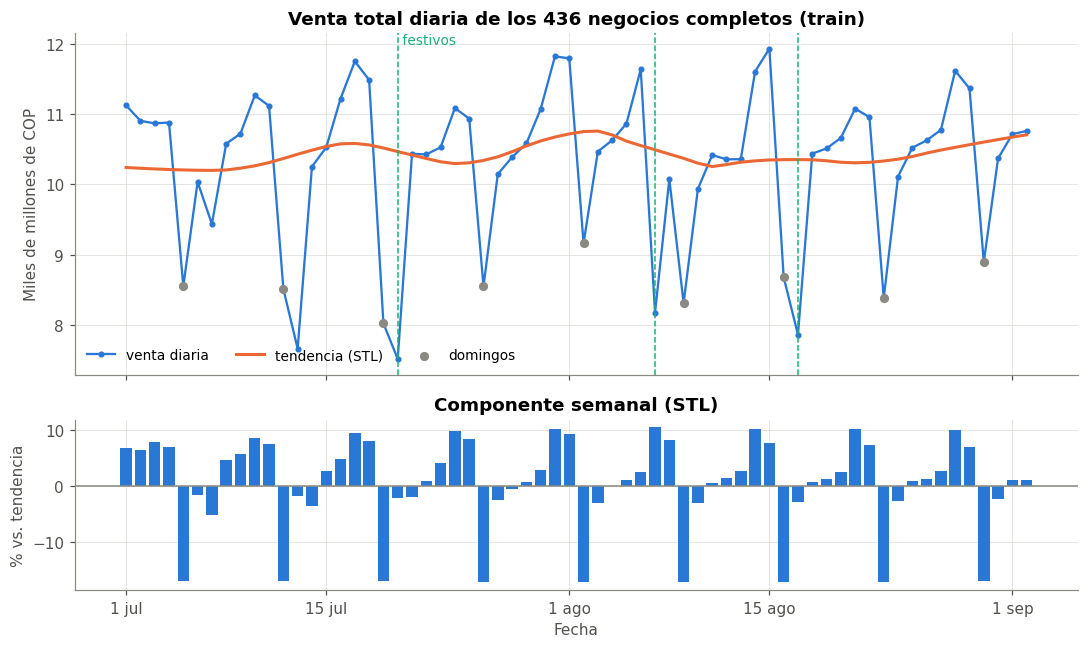

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]
ax.plot(agg.index, agg.values, color=AZUL, lw=1.5, marker="o", markersize=3, label="venta diaria")
ax.plot(agg.index, np.exp(stl.trend), color=NARANJA, lw=2, label="tendencia (STL)")
domingos = agg[agg.index.dayofweek == 6]
ax.scatter(domingos.index, domingos.values, color=GRIS, s=25, zorder=3, label="domingos")
for f in FESTIVOS:
    ax.axvline(f, color=VERDE, lw=1, ls="--")
ax.text(FESTIVOS[0], ax.get_ylim()[1], " festivos", color=VERDE, va="top", fontsize=9)
ax.set_title(f"Venta total diaria de los {len(completos)} negocios completos (train)")
ax.set_ylabel("Miles de millones de COP")
ax.legend(frameon=False, ncol=3, loc="lower left", fontsize=9)

ax = axes[1]
ax.bar(agg.index, np.exp(stl.seasonal) * 100 - 100, color=AZUL, width=0.8)
ax.axhline(0, color=GRIS, lw=1)
ax.set_title("Componente semanal (STL)")
ax.set_ylabel("% vs. tendencia")
ax.set_xlabel("Fecha")
fechas_eje(ax, agg.index)
plt.tight_layout()
plt.show()

### Interpretación

- La serie agregada tiene un **ciclo semanal muy marcado**. La descomposición STL (tendencia + estacionalidad de periodo 7 + residuo) le da a la estacionalidad semanal una **fuerza de 0,56**, y a la tendencia solo 0,04 (prácticamente plana).
- En dinero agregado, el **domingo** es claramente el día más bajo (~17 % bajo la tendencia) y de jueves a sábado el más alto. En el capítulo 4, mirando el negocio *típico*, lunes y domingo quedaban casi empatados. La diferencia se explica porque la serie agregada la dominan los negocios grandes (EDS), cuyo domingo cae más.
- Los tres festivos son de los días más bajos de la serie (se miden en 6.5).

## 🔁 6.2 Autocorrelación dentro de cada negocio

La autocorrelación (ACF) mide cuánto se parece la venta de un día a la de $k$ días antes. La parcial (PACF) mide lo mismo, descontando los rezagos intermedios. Se calcula **negocio por negocio** sobre `log1p(venta)`, sin los días de venta 0, y se resume con la mediana y el rango intercuartil entre negocios.

In [4]:
# [IA] ACF y PACF por negocio (serie en log sin ceros), resumidas entre negocios
NLAGS = 21
acfs, pacfs = [], []
for neg, d in train[train["venta_total"] > 0].groupby("negocio"):
    s = d.set_index("fecha")["y_log"].reindex(pd.date_range(d["fecha"].min(), d["fecha"].max()))
    if s.notna().sum() < 50:
        continue
    acfs.append(acf(s, nlags=NLAGS, missing="conservative")[1:])
    pacfs.append(pacf(s.interpolate(limit_direction="both"), nlags=NLAGS)[1:])
acfs, pacfs = np.array(acfs), np.array(pacfs)
banda = 1.96 / np.sqrt(train["fecha"].nunique())
print(f"negocios usados: {len(acfs)} | banda aprox. de significancia por negocio: ±{banda:.2f}")

res_acf = pd.DataFrame({"ACF mediana": np.median(acfs, axis=0), "PACF mediana": np.median(pacfs, axis=0),
                        "% negocios con ACF > banda": (acfs > banda).mean(axis=0) * 100},
                       index=range(1, NLAGS + 1)).rename_axis("rezago")
res_acf.loc[[1, 2, 3, 6, 7, 8, 13, 14, 21]]

negocios usados: 438 | banda aprox. de significancia por negocio: ±0.24


,ACF mediana,PACF mediana,% negocios con ACF > banda
rezago,,,
1,0.20,0.21,43.15
2,-0.04,-0.12,7.99
3,-0.12,-0.10,5.94
6,0.13,0.08,20.78
7,0.32,0.23,59.82
8,0.10,-0.04,16.21
13,0.10,0.05,11.87
14,0.19,0.05,41.32
21,0.14,0.05,27.17


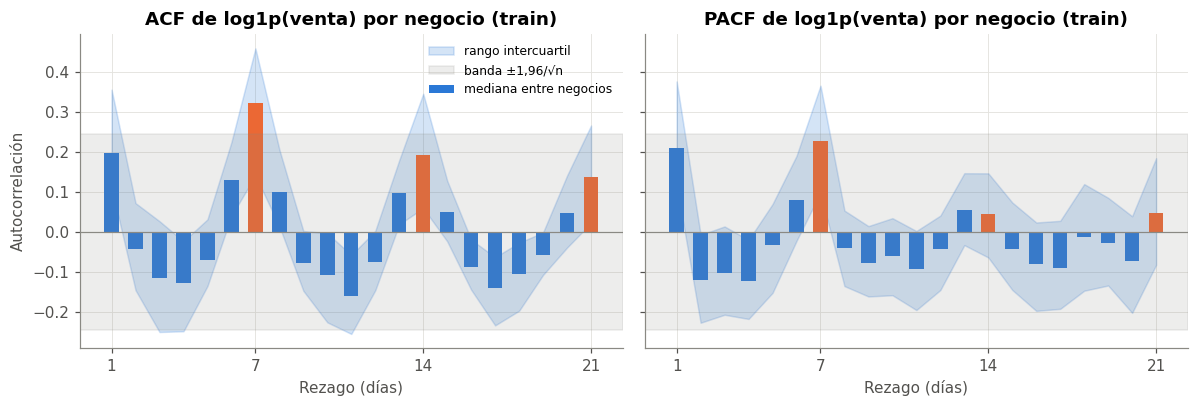

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
lags = np.arange(1, NLAGS + 1)
for ax, vals, nombre in [(axes[0], acfs, "ACF"), (axes[1], pacfs, "PACF")]:
    med = np.median(vals, axis=0)
    ax.fill_between(lags, np.percentile(vals, 25, axis=0), np.percentile(vals, 75, axis=0), color=AZUL, alpha=0.2, label="rango intercuartil")
    ax.bar(lags, med, color=[NARANJA if l % 7 == 0 else AZUL for l in lags], width=0.6, label="mediana entre negocios")
    ax.axhspan(-banda, banda, color=GRIS, alpha=0.15, label="banda ±1,96/√n")
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.set_xticks([1, 7, 14, 21])
    ax.set_title(f"{nombre} de log1p(venta) por negocio (train)")
    ax.set_xlabel("Rezago (días)")
axes[0].set_ylabel("Autocorrelación")
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

### Interpretación

- La ACF tiene **picos en 7, 14 y 21 días** (barras naranjas): el mismo día de la semana anterior se parece más que los días intermedios. Es la huella del ciclo semanal.
- El rezago 1 también es positivo: hay **persistencia de corto plazo** (una buena semana sigue siendo buena).
- La PACF tiene picos en 1 y en 7. Descontando los rezagos intermedios, la información útil está sobre todo en **ayer** y en **hace una semana**. El 14 aporta menos, pero sigue por encima de la banda en parte de los negocios.

**Decisiones →** rezagos **1, 7 y 14** (y no más largos, porque cada semana extra de rezago quita una semana de train). El **ingenuo estacional** ($\hat y_t = y_{t-7}$) es una línea base fuerte. Y como hay autocorrelación relevante hasta una semana, la validación cruzada usa un **gap de 7 días** (6.6).

## 📉 6.3 Estacionariedad

Se aplican dos pruebas complementarias a cada negocio (log1p, sin ceros):

- **ADF**: $H_0$ = la serie tiene raíz unitaria (no es estacionaria). Rechazar apoya la estacionariedad.
- **KPSS**: $H_0$ = la serie es estacionaria. Rechazar indica que no lo es.

Como son cientos de pruebas, los p-valores se corrigen con **Holm** dentro de cada familia.

In [6]:
# [IA] ADF y KPSS por negocio; con 64 días la potencia es baja, así que se leen juntas
filas = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # kpss avisa cuando el p-valor sale del rango de su tabla
    for neg, d in train[train["venta_total"] > 0].groupby("negocio"):
        s = d.sort_values("fecha")["y_log"].values
        if len(s) < 50:
            continue
        filas.append((neg, adfuller(s, maxlag=7, autolag="AIC")[1], kpss(s, regression="c", nlags="auto")[1]))
est = pd.DataFrame(filas, columns=["negocio", "p_adf", "p_kpss"])
est["adf_holm"] = multipletests(est["p_adf"], method="holm")[1]
est["kpss_holm"] = multipletests(est["p_kpss"], method="holm")[1]

resumen = pd.DataFrame({
    "sin corrección (%)": [(est["p_adf"] < 0.05).mean() * 100, (est["p_kpss"] < 0.05).mean() * 100],
    "con Holm (%)": [(est["adf_holm"] < 0.05).mean() * 100, (est["kpss_holm"] < 0.05).mean() * 100],
}, index=["ADF rechaza raíz unitaria (→ estacionaria)", "KPSS rechaza estacionariedad (→ no estacionaria)"])
print(f"negocios probados: {len(est)}")
print(f"serie agregada: ADF p = {adfuller(np.log(agg), maxlag=7, autolag='AIC')[1]:.3f}")
resumen

negocios probados: 438
serie agregada: ADF p = 0.209


,sin corrección (%),con Holm (%)
ADF rechaza raíz unitaria (→ estacionaria),60.73,46.80
KPSS rechaza estacionariedad (→ no estacionaria),20.78,0.00


### Interpretación

Con solo 64 días por serie, las pruebas tienen **poca potencia**: no rechazar no significa "no estacionaria" ni "estacionaria". Leídas juntas: ADF rechaza la raíz unitaria en el 61 % de los negocios (47 % con Holm), y KPSS rechaza la estacionariedad en el 21 % (ninguno después de Holm). Eso apunta a series **mayormente estacionarias en nivel** (en log), con algunos negocios con cambios de nivel. En la serie agregada ADF no rechaza (p = 0,21), algo esperable con 64 puntos y un ciclo semanal fuerte que la prueba no modela.

**Decisión →** no se diferencia la serie. Se modela el **nivel** en log con rezagos y medias móviles, que se adaptan a cambios lentos de nivel. Una media móvil de 7 días responde a un cambio de nivel en una semana.

## 🌊 6.4 Deriva dentro de train

¿Cambió el nivel de venta de los negocios entre el inicio y el final de train? Se compara, para cada negocio, la media en log de las **primeras 4 semanas** (1 – 28 jul) con la de las **últimas 4** (6 ago – 2 sep). Se usa Wilcoxon pareado entre negocios, con la correlación biserial por rangos como tamaño del efecto.

In [7]:
ini = train[train["fecha"] < "2026-07-29"].groupby("negocio")["y_log"].mean()
fin = train[train["fecha"] >= "2026-08-06"].groupby("negocio")["y_log"].mean()
ambos = pd.concat([ini, fin], axis=1, keys=["inicio", "final"]).dropna()
dif = ambos["final"] - ambos["inicio"]

res = stats.wilcoxon(dif)
rango = stats.rankdata(np.abs(dif))
r_rb = (rango[dif > 0].sum() - rango[dif < 0].sum()) / rango.sum()
print(f"negocios: {len(dif)} | cambio mediano: {np.expm1(dif.median()) * 100:+.1f} % | Wilcoxon p = {res.pvalue:.1e} | r biserial = {r_rb:+.2f}")
print(f"negocios que bajan más de 20 %: {(dif < np.log(0.8)).sum()} | que suben más de 20 %: {(dif > np.log(1.2)).sum()}")

negocios: 445 | cambio mediano: -0.4 % | Wilcoxon p = 1.8e-01 | r biserial = -0.07
negocios que bajan más de 20 %: 44 | que suben más de 20 %: 40


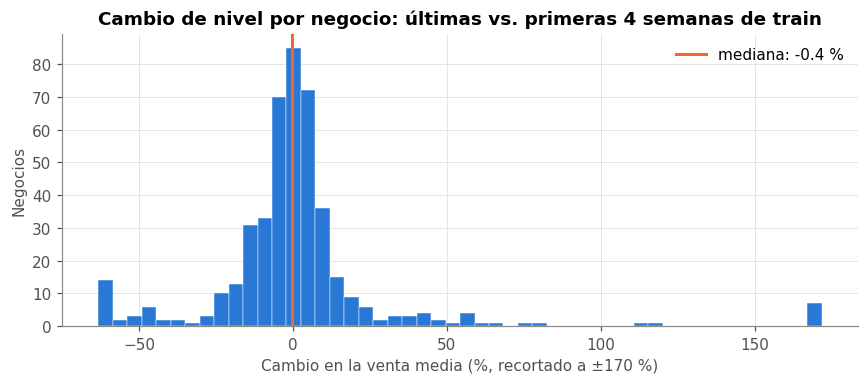

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(np.expm1(dif.clip(-1, 1)) * 100, bins=50, color=AZUL, edgecolor="white", linewidth=0.3)
ax.axvline(0, color=GRIS, lw=1)
ax.axvline(np.expm1(dif.median()) * 100, color=NARANJA, lw=2, label=f"mediana: {np.expm1(dif.median()) * 100:+.1f} %")
ax.set_title("Cambio de nivel por negocio: últimas vs. primeras 4 semanas de train")
ax.set_xlabel("Cambio en la venta media (%, recortado a ±170 %)")
ax.set_ylabel("Negocios")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Interpretación

**No hay una deriva sistemática**: el cambio mediano es −0,4 %, la prueba no lo detecta (p = 0,18) y el tamaño del efecto es despreciable ($r = -0{,}07$). Pero eso no significa que cada negocio sea estable: **44 negocios bajan más de 20 %** y **40 suben más de 20 %**. Hay cambios individuales grandes en ambas direcciones que se cancelan en el agregado.

Esto también explica la correlación ligeramente negativa del nivel histórico dentro del negocio (cap. 4). La media desde el inicio reacciona lento, así que en un negocio que cambia de nivel queda desfasada respecto a la venta actual.

**Decisiones →** (1) Las variables de **corto plazo** (rezago 1, rezago 7, media de 7 días) permiten que el modelo siga los cambios de nivel de cada negocio; el nivel histórico solo sirve como referencia de escala. (2) Un negocio que cambie de nivel en septiembre generará errores grandes unos días, hasta que los rezagos se pongan al día. Se revisa en los residuos del capítulo 8.

## 🎉 6.5 Festivos

Hay 3 festivos en train (lun 20 jul, vie 7 ago, lun 17 ago) y **ninguno en test**. Para cada festivo y negocio se compara la venta del festivo con la media del mismo día de la semana en las demás semanas de train (en log). Wilcoxon de una muestra y Holm sobre los 3 festivos.

In [9]:
# [IA] efecto de cada festivo vs. el mismo día de semana en semanas normales
pos = train[train["venta_total"] > 0].copy()
pos["dia"] = pos["fecha"].dt.dayofweek
normal = pos[~pos["fecha"].isin(FESTIVOS)].groupby(["negocio", "dia"])["y_log"].mean()
filas = []
for f in FESTIVOS:
    fest = pos[pos["fecha"] == f].set_index("negocio")["y_log"]
    ref = normal.xs(f.dayofweek, level="dia").reindex(fest.index)
    dif_f = (fest - ref).dropna()
    rango = stats.rankdata(np.abs(dif_f))
    filas.append((f.date(), DIAS[f.dayofweek], len(dif_f), np.expm1(dif_f.median()) * 100,
                  (rango[dif_f > 0].sum() - rango[dif_f < 0].sum()) / rango.sum(), stats.wilcoxon(dif_f).pvalue))
fest = pd.DataFrame(filas, columns=["festivo", "día", "negocios", "efecto mediano (%)", "r biserial", "p"])
fest["p Holm"] = multipletests(fest["p"], method="holm")[1]
formato_p(fest)

,festivo,día,negocios,efecto mediano (%),r biserial,p,p Holm
0,2026-07-20,lun,441,-14.75,-0.38,5.6e-12,1.1e-11
1,2026-08-07,vie,445,-22.94,-0.70,8.4e-38,2.5e-37
2,2026-08-17,lun,439,-15.30,-0.37,1.7e-11,1.7e-11


### Interpretación

Los tres festivos **bajan la venta**: −15 % los lunes festivos y −23 % el viernes 7 de agosto, frente al mismo día de la semana en semanas normales. Los tres son significativos después de Holm, con efectos de moderados a grandes ($|r|$ entre 0,37 y 0,70). Pero son **solo 3 días** y ninguno cae en test: el modelo puede aprender un coeficiente para `festivo`, pero no se puede evaluar si pronostica bien un festivo.

**Decisión →** se incluye la variable `festivo` (se conoce de antemano, cap. 5). Es una **limitación declarada**: con 3 casos su coeficiente es poco confiable, y su efecto en test es nulo porque no hay festivos.

## 🧩 6.6 Esquema de validación cruzada temporal

Con lo anterior se define la validación cruzada que se usa para elegir hiperparámetros (cap. 8):

| Elemento | Valor | Hallazgo que lo motiva |
|---|---|---|
| Esquema | `TimeSeriesSplit` sobre **días** (no filas) | Las filas de un día comparten choques comunes. Partir por días evita que el mismo día quede en train y en validación |
| Tamaño de validación | **7 días** | Ciclo semanal (6.1, 6.2): cada fold contiene cada día de la semana una vez |
| `gap` | **7 días** | ACF relevante hasta una semana (6.2): los días justo antes de la validación comparten choques con ella. Con el gap, la validación es más exigente que el uso real ($h = 1$), es decir **conservadora** |
| Número de folds | **4** | Con 50 días utilizables en train (64 menos 14 de calentamiento para el rezago 14), 4 folds dejan al menos 2 semanas de entrenamiento en el primero |
| Calentamiento | Las filas sin rezago 14 se excluyen | El rezago más largo es 14 días (6.2) |

fold 1: train 2026-07-15 a 2026-07-29 (15 días) | validación 2026-08-06 a 2026-08-12
fold 2: train 2026-07-15 a 2026-08-05 (22 días) | validación 2026-08-13 a 2026-08-19
fold 3: train 2026-07-15 a 2026-08-12 (29 días) | validación 2026-08-20 a 2026-08-26
fold 4: train 2026-07-15 a 2026-08-19 (36 días) | validación 2026-08-27 a 2026-09-02


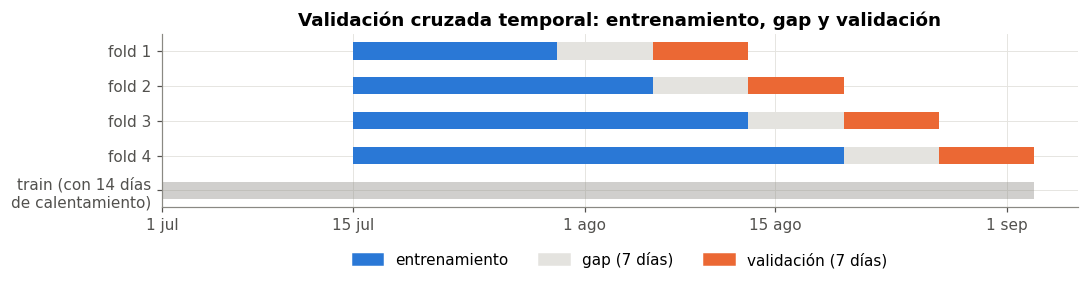

In [10]:
datos = datos_modelo(panel)
tr_mod = datos[datos["fecha"] <= CORTE].sort_values(["fecha", "negocio"]).reset_index(drop=True)
folds = folds_temporales(tr_mod["fecha"])

fig, ax = plt.subplots(figsize=(10, 2.8))
dias_tr = pd.Series(np.sort(tr_mod["fecha"].unique()))
for k, (i_tr, i_val) in enumerate(folds):
    f_tr, f_val = tr_mod["fecha"].iloc[i_tr], tr_mod["fecha"].iloc[i_val]
    ax.barh(k, (f_tr.max() - f_tr.min()).days + 1, left=f_tr.min(), color=AZUL, height=0.5)
    ax.barh(k, (f_val.min() - f_tr.max()).days - 1, left=f_tr.max() + pd.Timedelta(days=1), color="#e4e3df", height=0.5)
    ax.barh(k, (f_val.max() - f_val.min()).days + 1, left=f_val.min(), color=NARANJA, height=0.5)
    print(f"fold {k + 1}: train {f_tr.min().date()} a {f_tr.max().date()} ({f_tr.nunique()} días) | "
          f"validación {f_val.min().date()} a {f_val.max().date()}")
ax.barh(len(folds), (CORTE - INICIO).days + 1, left=INICIO, color=GRIS, height=0.5, alpha=0.4)
ax.set_yticks(list(range(len(folds))) + [len(folds)])
ax.set_yticklabels([f"fold {k + 1}" for k in range(len(folds))] + ["train (con 14 días\nde calentamiento)"])
ax.invert_yaxis()
ax.set_title("Validación cruzada temporal: entrenamiento, gap y validación")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="entrenamiento"), Patch(color="#e4e3df", label="gap (7 días)"),
                   Patch(color=NARANJA, label="validación (7 días)")], frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fechas_eje(ax, pd.date_range(INICIO, CORTE))
plt.tight_layout()
plt.show()

## ✅ Resumen del capítulo

| Hallazgo temporal | Decisión |
|---|---|
| Ciclo semanal fuerte (STL, ACF con picos en 7, 14, 21) | Día de la semana + rezagos 7 y 14 + línea base estacional |
| Persistencia de corto plazo (ACF y PACF en el rezago 1) | Rezago 1, media y desviación de 7 días; horizonte $h = 1$ |
| Series mayormente estacionarias en log (ADF/KPSS, baja potencia) | No diferenciar; modelar el nivel en log |
| Sin deriva global, pero cambios de nivel > 20 % en ~84 negocios | Variables de corto plazo; revisar los residuos en test |
| 3 festivos con caídas de 15–23 %, ninguno en test | Variable `festivo`, con la limitación declarada |
| Autocorrelación hasta una semana | CV temporal por días: 4 folds de 7 días con gap de 7 |

```{warning}
**Límites por tener solo ~3 meses.** No se puede estimar estacionalidad mensual ni anual (quincenas, primas, temporadas), ni validar el efecto de festivos fuera de muestra. La deriva observada en 9 semanas podría ser parte de un ciclo más largo que no se alcanza a ver.
```